# Not full Kalman filters but random stuff 

In [90]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [91]:
import matplotlib.pyplot as plt
import numpy as np

# from scipy.fft import fft, fftfreq
from cesium.math.stats import noise_vec
from cesium.signals.filters import LPF
from cesium.signals.frequency import freq_spectrum

## Low pass
https://en.wikipedia.org/wiki/Low-pass_filter#Simple_infinite_impulse_response_filter

In [102]:
dt = 0.01
nsteps = 100000
ts = np.arange(nsteps + 1) * dt  # [0:tf] inclusive so N+1 points

R = 2  # noise

ys = np.zeros((nsteps + 1, 2))

# Add a bunch of frequencies to it
for i in np.logspace(-3, 3, 40):
    ys[:, 0] += np.sin(ts * i)

for i in np.logspace(-3, 3, 40):
    ys[:, 1] += np.cos(ts * i * 1.1)

ys += noise_vec(R, nsteps + 1)[:, None]

# ys[:,1] *= 1.2
# ys[:,2] += 4

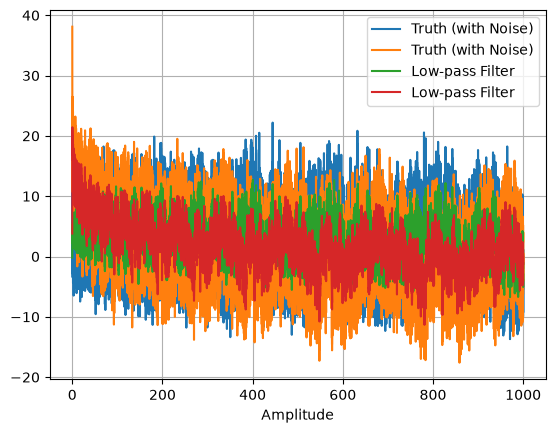

In [103]:
# Change this for different filter levels
# Higher alpha --> weight current measurement more
# Lower alpha --> More filter / weights previous measurements more
alpha = 0.1

low_pass = LPF(alpha)
ys_lp = [low_pass.run(x) for x in ys]


plt.plot(ts, ys, label="Truth (with Noise)")
plt.plot(ts, ys_lp, label="Low-pass Filter")
plt.xlabel("Time [s]")
plt.xlabel("Amplitude")
plt.legend()
plt.grid()
plt.show()
# Note how there's more lag the smaller alpha gets

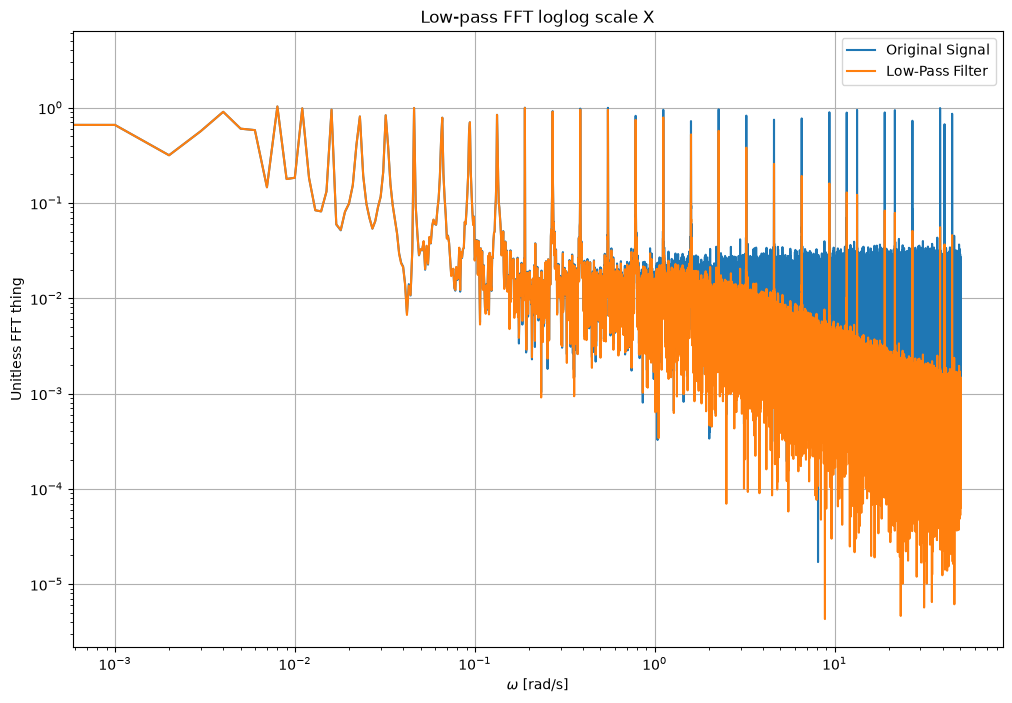

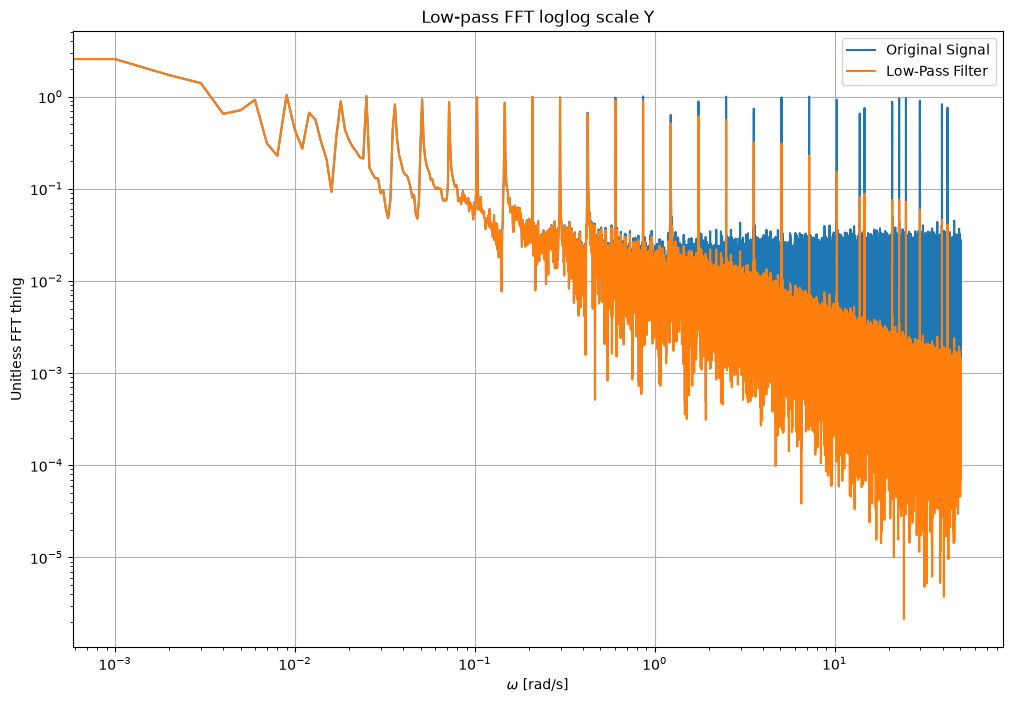

In [104]:
# fft
x_f, lp_f = freq_spectrum(ys_lp, dt)
_, freq_true = freq_spectrum(ys, dt)


labels = ["X", "Y"]

for i in range(2):
    plt.figure(figsize=(12, 8))
    plt.title(f"Low-pass FFT loglog scale {labels[i]}")
    plt.loglog(x_f, freq_true[:, i], color="tab:blue", label="Original Signal")
    plt.loglog(x_f, lp_f[:, i], color="tab:orange", label="Low-Pass Filter")
    plt.xlabel(r"$\omega$ [rad/s]")
    plt.ylabel("Unitless FFT thing")
    plt.legend()
    plt.grid()

## High pass
https://en.wikipedia.org/wiki/High-pass_filter#Algorithmic_implementation

In [105]:
# Change this for different filter levels
# Higher alpha --> weight current measurement more
# Lower alpha --> More filter / weights previous measurements more
alpha = 0.2

R = 20  # noise

# dt = 0.01
# nsteps = 1000

# ts = np.arange(nsteps + 1)*dt # [0:tf] inclusive so N+1 points

# ys = np.sin(ts)*15
# ys = [y + noise(R) for y in ys]

w = 15
# ys = np.sin(ts * 2*np.pi*w)*30 + noise_vec(R, nsteps + 1)

In [106]:
class HPF:
    def __init__(self, alpha: float):
        self.alpha = alpha
        self.x_prev = 0
        self.y = 0

    def run(self, x):
        self.y = self.alpha * self.y + self.alpha * (x - self.x_prev)
        self.x_prev = x

        return self.y

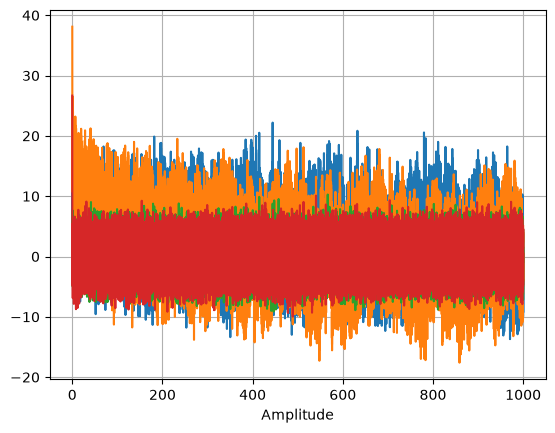

In [107]:
# Change this for different filter levels
# Higher alpha --> weight current measurement more
# Lower alpha --> More filter / weights previous measurements more
alpha = 0.7

R = 2 * np.eye(1)  # noise

high_pass = HPF(alpha)
ys_hp = [high_pass.run(x) for x in ys]

plt.plot(ts, ys, label="Truth (with Noise)")
plt.plot(ts, ys_hp, label="High-pass Filter")
plt.xlabel("Time [s]")
plt.xlabel("Amplitude")
plt.grid()
plt.show()

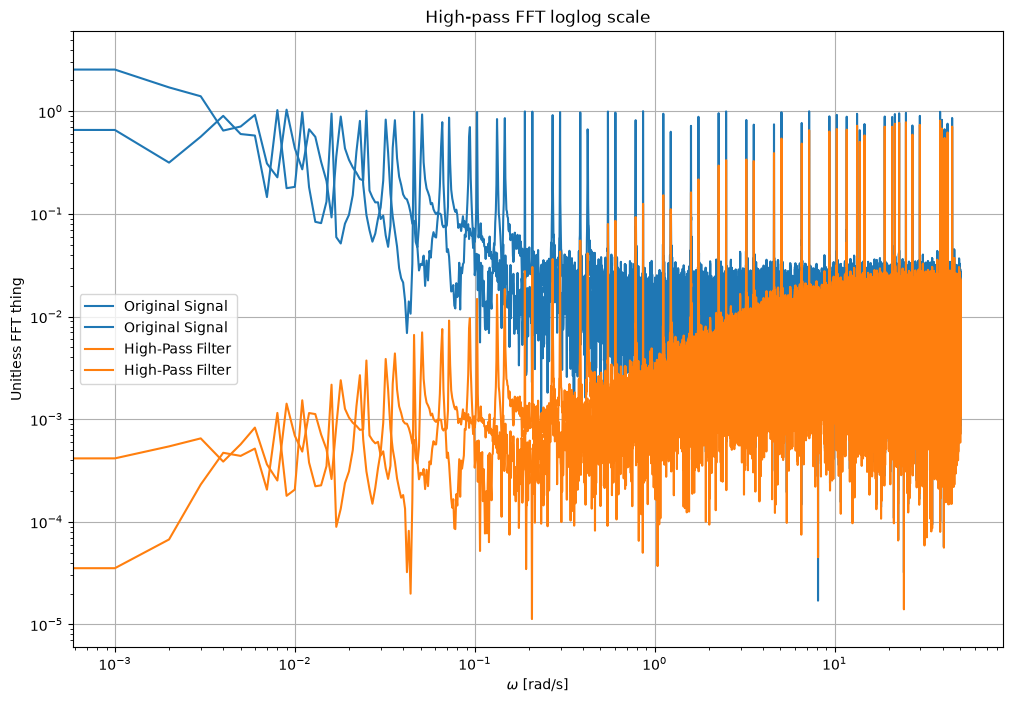

In [108]:
# fft
x_f, hp_f = freq_spectrum(ys_hp, dt)
_, freq_true = freq_spectrum(ys, dt)


plt.figure(figsize=(12, 8))
plt.title("High-pass FFT loglog scale")
plt.loglog(x_f, freq_true, color="tab:blue", label="Original Signal")
plt.loglog(x_f, hp_f, color="tab:orange", label="High-Pass Filter")
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel("Unitless FFT thing")
plt.legend()
plt.grid()

# plt.figure(figsize=(12,8))
# plt.title("High-pass FFT normal scale")
# plt.plot(x_f, freq_true, color="tab:blue",  label="Original Signal")
# plt.plot(x_f, hp_f, color="tab:orange", label="High-Pass Filter")
# plt.xlabel(r"$\omega$ [rad/s]")
# plt.ylabel("Unitless FFT thing")
# plt.legend()
# plt.grid()

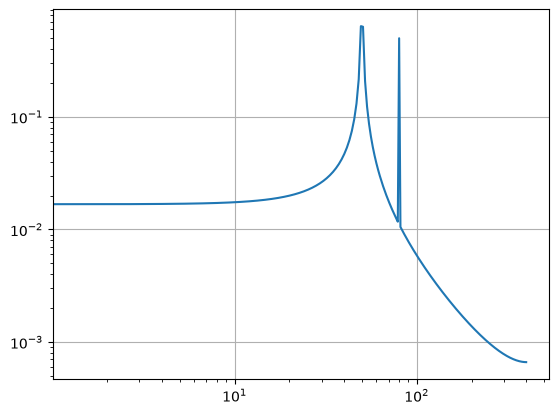

In [ ]:
# # Number of sample points
# N = 600
# # sample spacing
# T = 1.0 / 800.0
# x = np.linspace(0.0, N * T, N, endpoint=False)
# y = np.sin(50.0 * 2.0 * np.pi * x) + 0.5 * np.sin(80.0 * 2.0 * np.pi * x)
# yf = fft(y)
# xf = fftfreq(N, T)[: N // 2]
# plt.loglog(xf, 2.0 / N * np.abs(yf[0 : N // 2]))
# plt.grid()
# plt.show()